## **VALORGAS: Preprocessing of scans**

1. Read reconstructed volume
2. Check histogram
3. Decide on intensity bit depth and range
4. Export to OME-zarr

- Should be run on a node with enough memory - e.g. *bigmem*
- Should be run in an env. with qim3d installed

In [1]:
# Imports

import matplotlib.pyplot as plt
import numpy as np

# from insegt3d.volume.io import create_multiscale_zarr_from_numpy
import qim3d

## **1. Import**

In [2]:
# Folder
folderName = "/dtu/3d-imaging-center/projects/2025_DANFIX_160_VALORGAS/analysis/TBR-1-methanogen/"

In [3]:
# File
fileName = "TBR-1-methanogen_top_recon_padded.tif"

In [4]:
# Load data via qim3d
vol = qim3d.io.load(folderName + fileName, virtual_stack=True)
print(vol.shape)

Using virtual stack


(2000, 2000, 2000)


In [5]:
# set sample name
sample_name = "TBR-1-meth_top"
print(f"Converting {sample_name}")

Converting TBR-1-meth_top


## **2. Check histogram**

Subsampled volume has size 0.195% of the original volume.


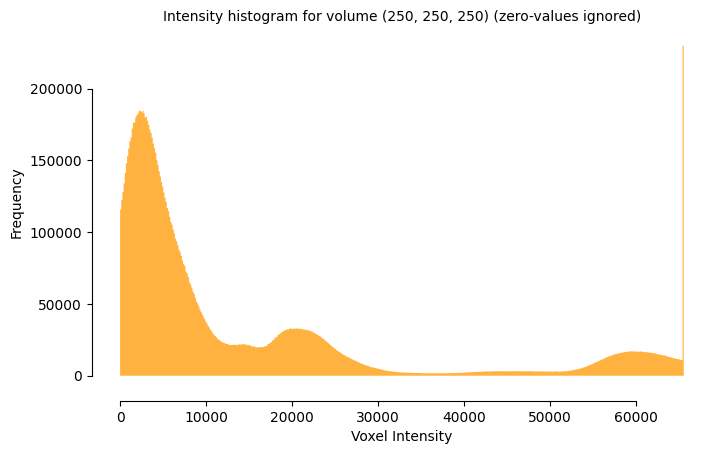

<Axes: title={'center': 'Intensity histogram for volume (250, 250, 250) (zero-values ignored)'}, xlabel='Voxel Intensity', ylabel='Frequency'>

In [7]:
qim3d.viz.histogram(vol, coarseness=8)

## **3. Decide on bit-depth compression**

In [6]:
# Set bounds

# -- Select -- #
min_cutoff = 0
max_cutoff = 65535
# ------------- #

Subsampled volume has size 0.195% of the original volume.


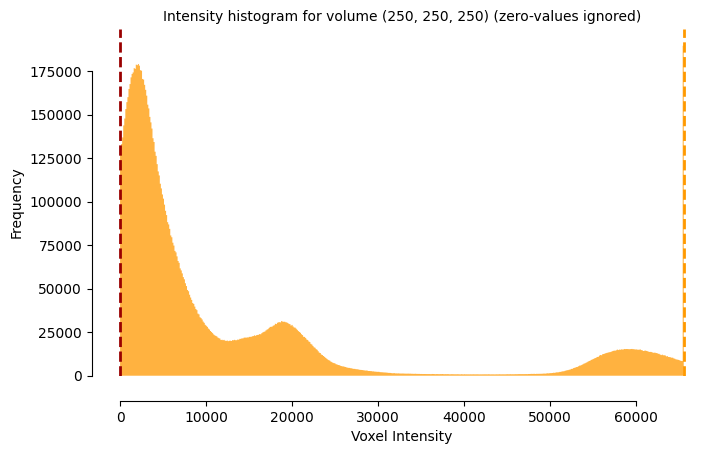

<Axes: title={'center': 'Intensity histogram for volume (250, 250, 250) (zero-values ignored)'}, xlabel='Voxel Intensity', ylabel='Frequency'>

In [7]:
# Get histogram
qim3d.viz.histogram(vol, coarseness=8, vertical_line=[min_cutoff, max_cutoff])

In [8]:
# Convert to uint8
# First rescale to range 0 and 1
newMin = 0
newMax = 1
volCompress = np.float16(vol)  # Ensure floating point
volCompress[volCompress < min_cutoff] = min_cutoff
volCompress[volCompress > max_cutoff] = max_cutoff
volCompress = (volCompress - min_cutoff) * (
    (newMax - newMin) / (max_cutoff - min_cutoff)
) + newMin

# Cast to uint8
volCompress = np.uint8(volCompress * 255)

/tmp/pbs.726284.hnode41/ipykernel_685841/4159164177.py:5: RuntimeWarning:

overflow encountered in cast

/tmp/pbs.726284.hnode41/ipykernel_685841/4159164177.py:7: RuntimeWarning:

overflow encountered in cast

/tmp/pbs.726284.hnode41/ipykernel_685841/4159164177.py:11: RuntimeWarning:

invalid value encountered in cast



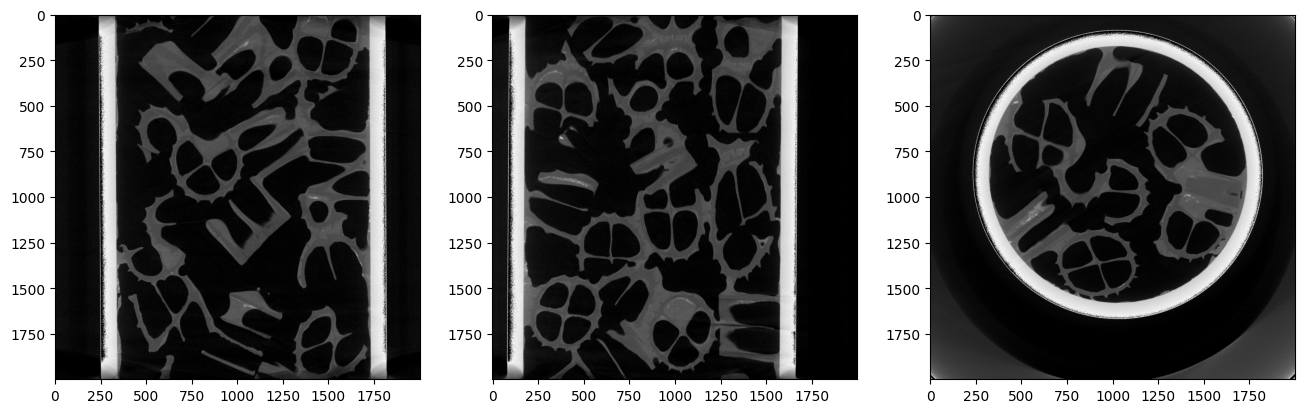

In [11]:
# Center-slice
cSlice = np.array(vol.shape) // 2
path_figure = f"{sample_name}_proc_central_slices.png"

# Show volume slices.
fig, ax = plt.subplots(1, 3, figsize=(16, 8))
ax[0].imshow(volCompress[..., cSlice[2]], cmap="gray", vmin=0, vmax=255)
ax[1].imshow(np.squeeze(volCompress[:, cSlice[1], :]), cmap="gray", vmin=0, vmax=255)
ax[2].imshow(
    np.transpose(np.squeeze(volCompress[cSlice[0], :, :])),
    cmap="gray",
    vmin=0,
    vmax=255,
)
fig.savefig(path_figure)

## **4. Convert and export**

In [13]:
# Set output folder
folder_out = "crops_zarr_TBR-1-m/"

# set path
export_path = folder_out + sample_name + "_ome.zarr"
print(f"Output file: {export_path}")

Output file: crops_zarr_TBR-1-m/TBR-1-meth_top_ome.zarr


In [14]:
qim3d.io.export_ome_zarr(
    export_path, volCompress, chunk_size=64, downsample_rate=2, replace=True
)

Exporting data to OME-Zarr format at crops_zarr_TBR-1-m/TBR-1-meth_top_ome.zarr
Number of scales: 6

Converting input data to Dask array
 - shape...: (2000, 2000, 2000)
 - chunks..: (64, 64, 64)

Calculating the multi-scale pyramid
- Scale 0: (2000, 2000, 2000)
- Scale 1: (1000, 1000, 1000)
- Scale 2: (500, 500, 500)
- Scale 3: (250, 250, 250)
- Scale 4: (125, 125, 125)
- Scale 5: (62, 62, 62)
Writing data to disk


Saving:   0%|          | 0.00/37.4k [00:00<?, ?Chunks/s]


All done!


In [20]:
# The insegt3d way to convert to ZARR
# create_multiscale_zarr_from_numpy(
#    volCompress,
#    export_path,
#    chunks=(64,64,64),
#    shards=(256,256,256)
# )